## Out-Of-Sample (OOS) Extension for SDR

Most optimal transport methods in general, do not provide a mechanism to move a new point from the source domain to the target domain. This requires re-solving the problem with the new point included as part of the input data to the OT solver. In this work, we provide an OOS extension by solving for an additional kernel ridge term. The OOS operator is defined as:

\begin{equation*}
    z(\cdot) = K(\cdot, X)L
\end{equation*}

where $L$ is a matrix of dimensions $\mathbb{R}^{n \times p}$ that is optimized for as part of the objective. $n$ denotes the number of points in the source domain and $p$ denotes the number of points in the target domain.

We will test this on a toy example to see, how SDR produces the intended behaviour and how the OOS extension can be used for downstream prediction tasks.

In [ ]:
import sys

# Allow importing modules from the parent directory
sys.path.append("..")

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_friedman1, make_s_curve, make_swiss_roll
from sklearn.model_selection import train_test_split
import torch

torch.set_default_dtype(torch.double)

# Create a synthetic dataset using the Swiss roll function
# X, y = make_s_curve(n_samples=500, noise=0.00, random_state=42)
X, y = make_swiss_roll(n_samples=500, noise=0.0, random_state=42)

train_x, test_x, train_y, test_y = train_test_split(X, y, shuffle=True, random_state=42)


def normalize(X):
    """
    Normalizes the input tensor X by subtracting the mean and
    dividing by the standard deviation along the first dimension (rows).
    """
    mean = X.mean(0, keepdim=True)
    std = X.std(0, keepdim=True)
    return (X - mean) / std


# Normalize the training and testing data
train_x, train_y, test_x, test_y = (
    normalize(torch.tensor(train_x)),
    normalize(torch.tensor(train_y)).unsqueeze(-1),
    normalize(torch.tensor(test_x)),
    normalize(torch.tensor(test_y)).unsqueeze(-1),
)

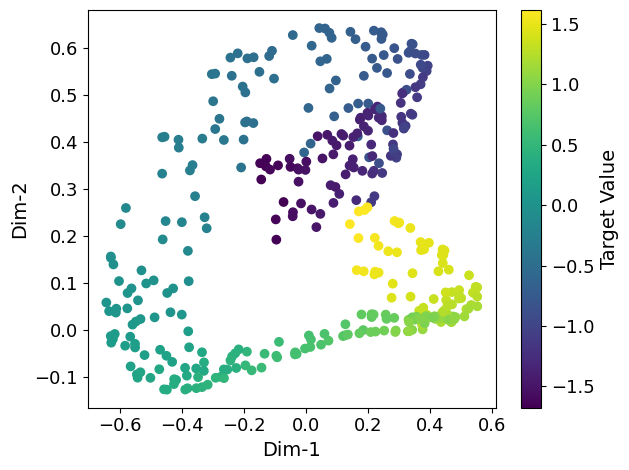

In [ ]:
LABEL_FONT_SIZE = 14
TICK_FONT_SIZE = 13

from src.kernel_supervised_pca import KernelSupervisedPCA

# Test with Kernel Supervised PCA and visualise the reprsentation produced
kpca = KernelSupervisedPCA(n_components=2)
embedding = kpca.fit_transform(train_x, train_y)

plt.scatter(embedding[:, 0], embedding[:, 1], c=train_y, cmap="viridis")
plt.xlabel(
    "Dim-1",
    fontsize=LABEL_FONT_SIZE,
)
plt.ylabel("Dim-2", fontsize=LABEL_FONT_SIZE)
cbar = plt.colorbar(label="Target Value")
cbar.ax.tick_params(labelsize=TICK_FONT_SIZE)
cbar.set_label("Target Value", fontsize=LABEL_FONT_SIZE)
plt.tick_params(axis="both", labelsize=TICK_FONT_SIZE)
plt.tight_layout()
plt.show()
# plt.savefig("swissroll_kspca.pdf", format="pdf")

/Users/saiaakashramesh/Library/Caches/pypoetry/virtualenvs/distributional-reduction-BVcFI9L--py3.12/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


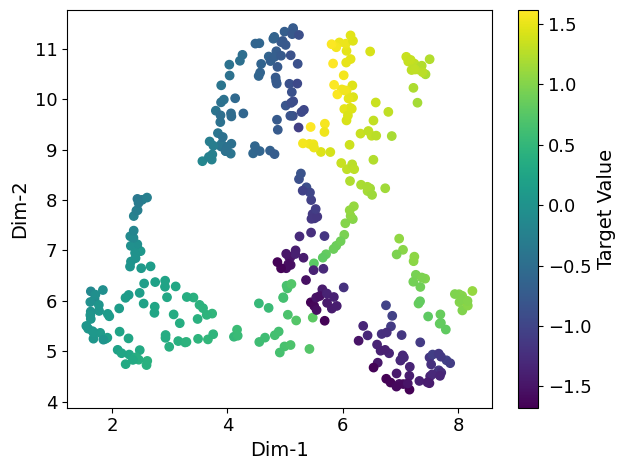

In [ ]:
LABEL_FONT_SIZE = 14
TICK_FONT_SIZE = 13

import umap
import matplotlib.pyplot as plt

# Run UMAP
embedding = umap.UMAP(
    n_neighbors=50,
    min_dist=0.1,
    n_components=2,
    random_state=42,
).fit_transform(train_x, y=train_y)

# Visualize the UMAP embedding
plt.scatter(embedding[:, 0], embedding[:, 1], c=train_y, cmap="viridis")
plt.xlabel(
    "Dim-1",
    fontsize=LABEL_FONT_SIZE,
)
plt.ylabel("Dim-2", fontsize=LABEL_FONT_SIZE)
cbar = plt.colorbar(label="Target Value")
cbar.ax.tick_params(labelsize=TICK_FONT_SIZE)
cbar.set_label("Target Value", fontsize=LABEL_FONT_SIZE)
plt.tick_params(axis="both", labelsize=TICK_FONT_SIZE)
plt.tight_layout()
plt.show()
# plt.savefig("swissroll_umap.pdf", format="pdf")

In [ ]:
from src.sdr import SDR
from src.affinities import (
    NormalizedGaussianAndStudentAffinity,
    SymmetricEntropicAffinity,
)

# Run SDR on the Swiss roll dataset
dr = SDR(
    affinity_data=SymmetricEntropicAffinity(perp=50, lr=0.01),
    affinity_embedding=NormalizedGaussianAndStudentAffinity(student=True),
    hsic_kernel_z="rq",
    hsic_kernel_y="rbf",
    fgw_loss="square_loss",
    loss_fun="kl_loss",
    alpha=0.2,
    output_sam=train_x.shape[-2],
    output_dim=2,
    max_iter_outer=20,
    tol=1e-5,
    lambda_hsic=1000.0,
)

Z, L = dr.fit_transform(train_x, train_y)

In [ ]:
# Project the test data into the learned representation space using L
Z_test = dr.transform(test_x)

/Users/saiaakashramesh/Distributional-Reduction/notebooks/../src/kernels.py:89: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  sigma2 = torch.tensor(sigma * sigma).clamp_min(eps)


In [ ]:
from src.hsic_loss import hsic

# Compute HSIC values for the training and testing data and compare them with the original data
hsic_X_train = hsic(
    train_x,
    train_y,
    kernel_z="rbf",
    kernel_y="rbf",
)
hsic_Z_train = hsic(Z, train_y, kernel_y="rbf")

hsic_X_test = hsic(test_x, test_y, kernel_y="rbf")
hsic_Z_test = hsic(Z_test, test_y, kernel_y="rbf")

print(f"HSIC(X_train, Y) = {hsic_X_train:.4f}")
print(f"HSIC(Z_train, Y) = {hsic_Z_train:.4f}")
print(f"HSIC(X_test, Y) = {hsic_X_test:.4f}")
print(f"HSIC(Z_test, Y) = {hsic_Z_test:.4f}")

HSIC(X_train, Y) = 0.2294
HSIC(Z_train, Y) = 0.9959


In [ ]:
from sklearn.preprocessing import StandardScaler

# Scale the learned representation Z to have zero mean and unit variance
scaler = StandardScaler().fit(Z.detach().cpu().numpy())
Zs = scaler.transform(Z.detach().cpu().numpy())

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.kernel_ridge import KernelRidge

## Use a K-Nearest Neighbors regressor to fit the learned representation Z to the target variable train_y.
# knn = KNeighborsRegressor(n_neighbors=20)
# knn.fit(Zs, train_y.detach().numpy())

## Use a Kernel Ridge regressor to fit the learned representation Z to the target variable train_y.
krr = KernelRidge(kernel="rbf", alpha=1.5)
krr.fit(Zs, train_y.detach().numpy())

/Users/saiaakashramesh/Library/Caches/pypoetry/virtualenvs/distributional-reduction-BVcFI9L--py3.12/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saiaakashramesh/Library/Caches/pypoetry/virtualenvs/distributional-reduction-BVcFI9L--py3.12/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saiaakashramesh/Library/Caches/pypoetry/virtualenvs/distributional-reduction-BVcFI9L--py3.12/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


KernelRidge(alpha=1.5, kernel='rbf')

In [ ]:
## Evaluate the training performance of the Kernel Ridge regressor using the R-squared metric.

# train_r2 = knn.score(Zs, train_y.detach().cpu().numpy())
train_r2 = krr.score(Zs, train_y.detach().cpu().numpy())
print("Train R2:", train_r2)

Train R2: 0.9895091643316511


/Users/saiaakashramesh/Library/Caches/pypoetry/virtualenvs/distributional-reduction-BVcFI9L--py3.12/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saiaakashramesh/Library/Caches/pypoetry/virtualenvs/distributional-reduction-BVcFI9L--py3.12/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saiaakashramesh/Library/Caches/pypoetry/virtualenvs/distributional-reduction-BVcFI9L--py3.12/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


In [ ]:
test_zs = scaler.transform(Z_test.detach().cpu().numpy())

## Evaluate the testing performance of the Kernel Ridge regressor using the R-squared metric.

# test_r2 = knn.score(test_zs, test_y.detach().cpu().numpy())
test_r2 = krr.score(test_zs, test_y.detach().cpu().numpy())
print("Test R2:", test_r2)

Test R2: 0.9819228723527857


/Users/saiaakashramesh/Library/Caches/pypoetry/virtualenvs/distributional-reduction-BVcFI9L--py3.12/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saiaakashramesh/Library/Caches/pypoetry/virtualenvs/distributional-reduction-BVcFI9L--py3.12/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saiaakashramesh/Library/Caches/pypoetry/virtualenvs/distributional-reduction-BVcFI9L--py3.12/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


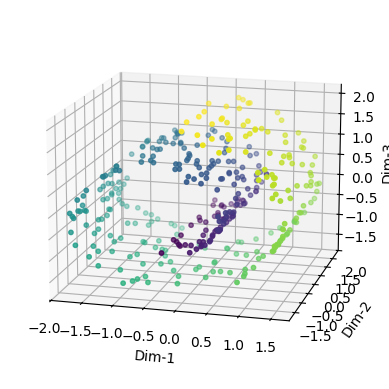

In [ ]:
import matplotlib.pyplot as plt

# Visualize the original Swiss roll data in 3D
ax = plt.figure().add_subplot(projection="3d")
ax.scatter(
    train_x[:, 0],
    train_x[:, 1],
    train_x[:, 2],
    train_y.squeeze(),
    c=train_y.squeeze(),
    cmap="viridis",
    s=10,
)
ax.view_init(elev=15.0, azim=-75, roll=0)
ax.set_xlabel("Dim-1")
ax.set_ylabel("Dim-2")
ax.set_zlabel("Dim-3")
# ax.set_title("Original Data")

plt.show()
# plt.savefig("swissroll_original.pdf", format="pdf")

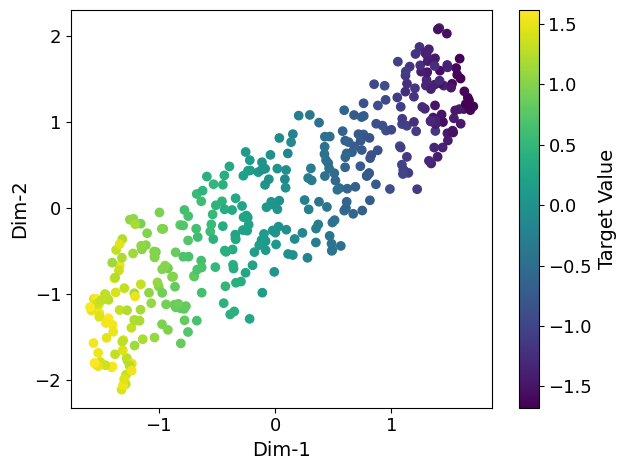

In [ ]:
import matplotlib.pyplot as plt

# Visualize the SDR learned representation Z in 2D
plt.scatter(Zs[:, 0], Zs[:, 1], c=train_y, cmap="viridis")
plt.xlabel(
    "Dim-1",
    fontsize=LABEL_FONT_SIZE,
)
plt.ylabel("Dim-2", fontsize=LABEL_FONT_SIZE)
cbar = plt.colorbar(label="Target Value")
cbar.ax.tick_params(labelsize=TICK_FONT_SIZE)
cbar.set_label("Target Value", fontsize=LABEL_FONT_SIZE)
plt.tick_params(axis="both", labelsize=TICK_FONT_SIZE)
plt.tight_layout()
plt.show()
# plt.savefig("swissroll_sdr.pdf", format="pdf")

/Users/saiaakashramesh/Library/Caches/pypoetry/virtualenvs/distributional-reduction-BVcFI9L--py3.10/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saiaakashramesh/Library/Caches/pypoetry/virtualenvs/distributional-reduction-BVcFI9L--py3.10/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saiaakashramesh/Library/Caches/pypoetry/virtualenvs/distributional-reduction-BVcFI9L--py3.10/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


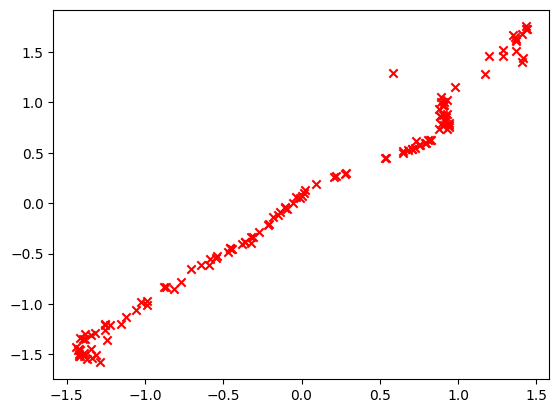

In [ ]:
## Visualize the predicted vs actual target values for the test data using the Kernel Ridge regressor
pred = krr.predict(test_zs)
plt.scatter(pred, test_y, c="red", marker="x")